In [1]:
from pathlib import Path
from scipy.io import loadmat
import pandas as pd
from pathlib import Path
from paths_data import path_to_PBLT
import importlib
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from behavorial_organize_data import FEEDBACK_CODES
from electrodes_lebelling_masks import get_chanlist_from_info , classify_contacts_insula  ,bipolar_to_monopolar
from behavorial_organize_data import classify_outcome, expected_feedback_status, OUTCOME_LABELS, OUTCOME_REWARDS
from load_tfr_data import get_sampling_rate , load_patient ,get_hdr_info , load_tfr_data_wya
from behavorial_organize_data import load_pos_file , get_pos_file_path
from pprint import pprint
from signal_processing import integrate_time , integrate_frequency
from signal_processing import baseline_div, baseline_zscore
from behavorial_organize_data import  PICTURE_CODES , reconstruct_trials
from plot_data import plot_tfr

In [2]:
patient = "GRE_2014_AUDe_PBLT"
header, tfr_path = load_patient(patient, path_to_PBLT)
wya_path = tfr_path


##  Plot some tfr around tasks

In [3]:
import numpy as np
info = get_hdr_info(header)

N_trial, N_chan, N_freqs, N_time, dimsize, times, freqs = (
    info[k] for k in ["N_trial", "N_chan", "N_freqs", "N_time",
                      "dimsize", "times", "freqs"])

data = load_tfr_data_wya(wya_path, N_trial, N_chan, N_freqs, N_time)
print("Dimensions :", data.shape)
print("Min / max :", np.nanmin(data), np.nanmax(data))

Dimensions : (576, 166, 58, 82)
Min / max : -9.790754 73.560555


### Baseline the signal and get mean

In [4]:
times
t_min_baseline = times[0]
t_max_baseline = - 2

# data_z_score = baseline_zscore(data, times, t_min_baseline, t_max_baseline)
data_div = baseline_div(data, times, t_min_baseline, t_max_baseline)

# tfr_mean_div = np.nanmean(data_div, axis=(0, -1))  # Moyenne sur tous les essais et canaux


### Plot 1 random channel of 1 patient

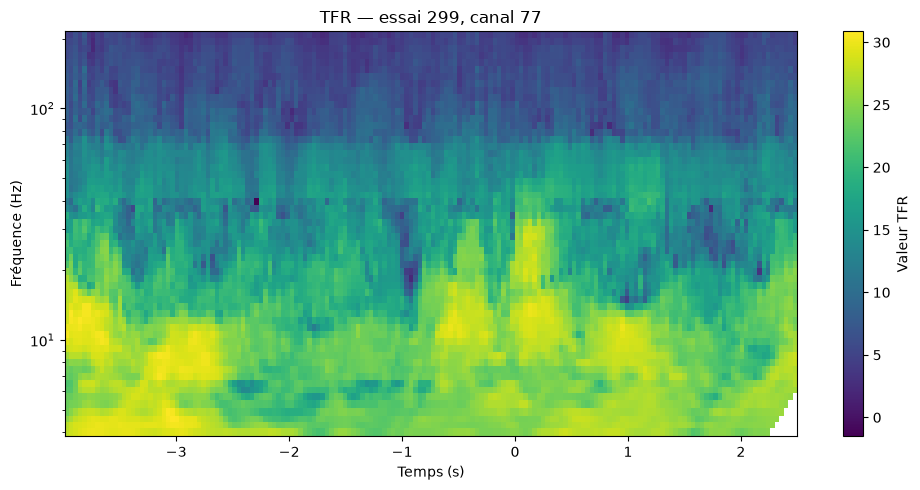

In [5]:


trial = np.random.randint(0, data.shape[0])  # Sélection aléatoire d'un essai
channel = np.random.randint(0, data.shape[3])  # Sélection aléatoire d'un canal

data = np.array(data, dtype=np.float32)  # Assurez-vous que les données sont en float32
tfr = data[trial, :, :, channel]
tfr_base_zscore = data_div[trial, :, :, channel]
plot_tfr(tfr, times, freqs, trial, channel)
# plot_tfr(tfr_base_zscore, times, freqs, trial, channel)

### Pot tfr mean across all trials:

In [6]:
# plot_tfr(tfr_mean, times, freqs, "Moyenne", "Moyenne")
#plot baseline zscore meanstd =
# plot_tfr(tfr_mean_div, times, freqs, "Moyenne z-score", "Moyenne z-score")

In [7]:
patient = patient.removesuffix("_PBLT")  # Supprime le suffixe "_PBLT" si présent

pos_file_path = get_pos_file_path(patient, path_to_PBLT)
data_behav = load_pos_file(pos_file_path)


In [8]:

# Le fichier .pos du patient déjà sélectionné dans le notebook
pos_file_path = Path(path_to_PBLT) / patient / f"{patient}_PBLT.pos"

path_to_config_json = Path(path_to_PBLT) / "config.json"
sampling_rate = get_sampling_rate(path_to_config_json, patient)

events_df = load_pos_file(pos_file_path ,sampling_rate=sampling_rate) 

print(f"Nombre d'événements : {len(events_df)}")
display(events_df.head(10))

Nombre d'événements : 2960


,time,code,event_row
0,43.453125,2,0
1,47.809570,2,1
2,54.681641,2,2
3,63.530273,1,3
4,72.603516,2,4
5,80.488281,2,5
6,103.226562,2,6
7,115.088867,2,7
8,115.125000,25,8
9,115.975586,26,9


In [9]:
PICTURE_CODES

{12: ('gain', 'up', 1),
 17: ('gain', 'up', 1),
 22: ('gain', 'down', 2),
 27: ('gain', 'down', 2),
 32: ('loss', 'up', 1),
 37: ('loss', 'up', 1),
 42: ('loss', 'down', 2),
 47: ('loss', 'down', 2)}

In [10]:

trials_df = reconstruct_trials(events_df)

## Attribute to each feedback the category

In [11]:
trials_df

,picture_time,picture_code,feedback_time,feedback_code,response,reaction_time,n_button_presses,response_codes,response_time,condition,direction,expected_response,response_matches_picture
0,116.492188,27,119.742188,29,1.0,1.972656,1,[1],118.464844,gain,down,2,False
1,122.742188,12,126.326172,13,1.0,2.324219,1,[1],125.066406,gain,up,1,True
2,129.326172,47,132.292969,49,2.0,1.720703,1,[2],131.046875,loss,down,2,True
3,135.209961,17,139.644531,18,1.0,3.190430,1,[1],138.400391,gain,up,1,True
4,142.710938,17,145.427734,18,1.0,1.469727,1,[1],144.180664,gain,up,1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,3760.065430,27,3762.048828,29,2.0,0.924805,2,"[2, 2]",3760.990234,gain,down,2,True
572,3764.932617,32,3766.749023,34,2.0,0.574219,1,[2],3765.506836,loss,up,1,False
573,3769.999023,17,3773.199219,19,1.0,1.944336,1,[1],3771.943359,gain,up,1,True
574,3776.349609,37,3778.616211,38,1.0,1.022461,1,[1],3777.372070,loss,up,1,True


In [12]:
trials_df["outcome_category"] = trials_df.apply(classify_outcome, axis=1)
trials_df["outcome_label"] = trials_df["outcome_category"].map(OUTCOME_LABELS)
trials_df["reward_euro"] = trials_df["outcome_category"].map(OUTCOME_REWARDS)

# Contrôle complémentaire : le feedback indique-t-il le même statut
# que la comparaison entre réponse observée et réponse attendue ?


trials_df["feedback_says_correct"] = trials_df.apply(
    expected_feedback_status, axis=1
) # does the feedback indicate that the response of patient was correct or not? (True/False)
trials_df["response_feedback_agree"] = (
    trials_df["response_matches_picture"]
    == trials_df["feedback_says_correct"] # does the feedback agree with the response? (True/False)
)

display(trials_df[[
    "picture_code", "response_codes", "response",
    "expected_response", "feedback_code", "condition",
    "outcome_category", "reward_euro", "response_feedback_agree" , "feedback_code"
]].head(20))
print("number of trial with feedback", trials_df["feedback_code"].notnull().sum())

,picture_code,response_codes,response,expected_response,feedback_code,condition,outcome_category,reward_euro,response_feedback_agree,feedback_code
0,27,[1],1.0,2,29,gain,0.0,0.0,True,29
1,12,[1],1.0,1,13,gain,2.0,1.0,True,13
2,47,[2],2.0,2,49,loss,3.0,0.0,True,49
3,17,[1],1.0,1,18,gain,2.0,1.0,True,18
4,17,[1],1.0,1,18,gain,2.0,1.0,True,18
5,22,[2],2.0,2,23,gain,2.0,1.0,True,23
6,12,[1],1.0,1,13,gain,2.0,1.0,True,13
7,32,[1],1.0,1,34,loss,3.0,0.0,True,34
8,17,[1],1.0,1,18,gain,2.0,1.0,True,18
9,27,[2],2.0,2,29,gain,0.0,0.0,False,29


number of trial with feedback 576


Associer les essais aux TFR et créer l’array de taille

In [13]:
# Les TFR MATLAB en mode "outcome" sont associées aux feedbacks
# dans l'ordre chronologique, après exclusion des autres événements.

tfr_trials_df = (
    trials_df.dropna(subset=["feedback_code"])
    .sort_values("feedback_time")
    .reset_index(drop=True)
    .copy()
)

n_tfr = data.shape[0]
n_behavioral = len(tfr_trials_df)

print(f"Nombre de TFR             : {n_tfr}")
print(f"Essais avec feedback      : {n_behavioral}")
print(f"Nombre de feedbacks .pos  : {events_df['code'].isin(FEEDBACK_CODES).sum()}")

if n_tfr != n_behavioral:
    raise ValueError(
        "Le nombre de TFR et d'essais comportementaux diffère. "
        "Ne pas associer automatiquement : inspecter les événements "
        "manquants, les essais incomplets et l'ordre des fichiers."
    )

# Index explicite du trial TFR : 0 correspond à data[0]
tfr_trials_df.insert(0, "tfr_trial_index", np.arange(n_tfr))

# Array entier de taille N_trial :
# 0 = échec gain, 1 = échec perte,
# 2 = réussite gain, 3 = réussite perte.
# -1 = catégorie non attribuable (si le feedback n'est pas classifiable).
trial_outcome_array = (
    tfr_trials_df["outcome_category"]
    .fillna(-1)
    .astype(int)
    .to_numpy()
)

trial_reward_array = tfr_trials_df["reward_euro"].to_numpy()

assert len(trial_outcome_array) == N_trial
assert len(trial_reward_array) == N_trial

print("Taille de trial_outcome_array :", trial_outcome_array.shape)
print("Catégories présentes :", np.unique(trial_outcome_array))
print("Récompenses présentes :", np.unique(trial_reward_array[~pd.isna(trial_reward_array)]))

display(tfr_trials_df[[
    "tfr_trial_index", "picture_code", "response",
    "feedback_code", "outcome_category", "outcome_label", "reward_euro"
]].head(15))

Nombre de TFR             : 576
Essais avec feedback      : 576
Nombre de feedbacks .pos  : 576
Taille de trial_outcome_array : (576,)
Catégories présentes : [-1  0  1  2  3]
Récompenses présentes : [-1.  0.  1.]


,tfr_trial_index,picture_code,response,feedback_code,outcome_category,outcome_label,reward_euro
0,0,27,1.0,29,0.0,gain_failure_0_euro,0.0
1,1,12,1.0,13,2.0,gain_success_plus_1_euro,1.0
2,2,47,2.0,49,3.0,loss_success_0_euro,0.0
3,3,17,1.0,18,2.0,gain_success_plus_1_euro,1.0
4,4,17,1.0,18,2.0,gain_success_plus_1_euro,1.0
5,5,22,2.0,23,2.0,gain_success_plus_1_euro,1.0
6,6,12,1.0,13,2.0,gain_success_plus_1_euro,1.0
7,7,32,1.0,34,3.0,loss_success_0_euro,0.0
8,8,17,1.0,18,2.0,gain_success_plus_1_euro,1.0
9,9,27,2.0,29,0.0,gain_failure_0_euro,0.0


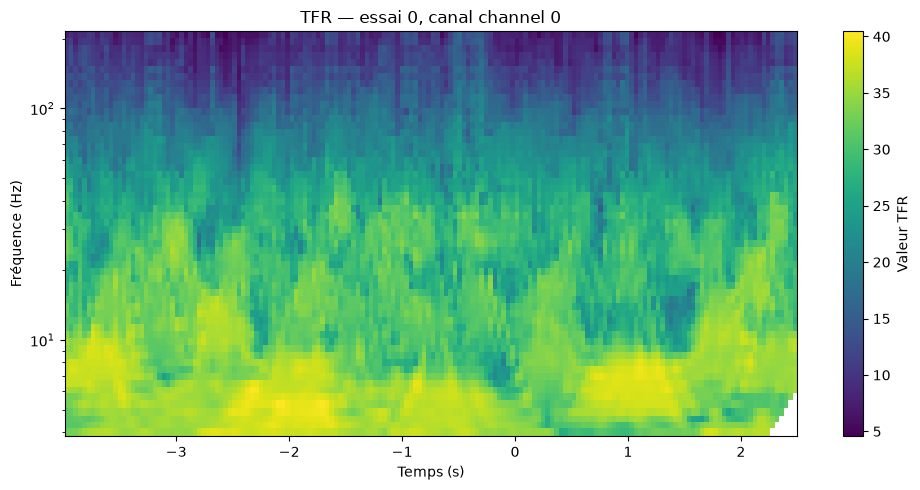

tfr_trial_index                               0
picture_time                         116.492188
picture_code                                 27
feedback_time                        119.742188
feedback_code                                29
response                                    1.0
reaction_time                          1.972656
n_button_presses                              1
response_codes                              [1]
response_time                        118.464844
condition                                  gain
direction                                  down
expected_response                             2
response_matches_picture                  False
outcome_category                            0.0
outcome_label               gain_failure_0_euro
reward_euro                                 0.0
feedback_says_correct                     False
response_feedback_agree                    True
Name: 0, dtype: object


In [14]:
# Exemple : TFR du trial 0 et sa réponse comportementale
trial_idx = 0

plot_tfr(
    data[trial_idx, :, :, 0],  # adapter selon la signature de ta fonction
    times,
    freqs,
    trial_idx,
    "channel 0"
)

print(tfr_trials_df.iloc[trial_idx])

## Contrôles qualité avant toute analyse
je remarque que les données comportementales semblent ne pas correspondre à la fiche de la tâche imprimée, correct quand response != expected response  et inversement

In [15]:
print("=== Contrôle des données comportementales ===")
print("Nombre de TFR :", N_trial)
print("Nombre d'essais reconstruits :", len(trials_df))
print("Nombre d'essais avec feedback :", len(tfr_trials_df))

print("\n=== Catégories de résultat ===")
display(
    tfr_trials_df["outcome_label"]
    .value_counts(dropna=False)
    .rename_axis("catégorie")
    .to_frame("nombre")
)

print("\n=== Essais avec plusieurs appuis ===")
display(
    trials_df.loc[
        trials_df["n_button_presses"] > 1,
        ["picture_code", "response_codes", "response",
         "expected_response", "feedback_code"]
    ].head(20)
)

print("\n=== Essais dont la réponse et le feedback semblent incohérents ===")
display(
    trials_df.loc[
        trials_df["response"].notna()
        & trials_df["feedback_says_correct"].notna()
        & ~trials_df["response_feedback_agree"],
        ["picture_code", "response_codes", "response",
         "expected_response", "feedback_code",
         "feedback_says_correct"]
    ].head(20)
)

print("\n=== Essais sans feedback ===")
display(trials_df[trials_df["feedback_code"].isna()])

=== Contrôle des données comportementales ===
Nombre de TFR : 576
Nombre d'essais reconstruits : 576
Nombre d'essais avec feedback : 576

=== Catégories de résultat ===


,nombre
catégorie,
gain_success_plus_1_euro,185
loss_success_0_euro,176
loss_failure_minus_1_euro,112
gain_failure_0_euro,102
NaN,1



=== Essais avec plusieurs appuis ===


,picture_code,response_codes,response,expected_response,feedback_code
78,47,"[2, 2]",2.0,2,49
79,32,"[2, 2]",2.0,1,34
297,32,"[2, 2]",2.0,1,34
298,12,"[2, 2]",2.0,1,14
315,32,"[2, 2]",2.0,1,34
352,42,"[2, 1]",1.0,2,43
384,12,"[1, 2]",2.0,1,13
478,47,"[1, 2]",2.0,2,49
479,42,"[1, 2]",2.0,2,44
480,42,"[1, 2, 2, 2, 1, 2, 1, 2, 1, 2, 1]",1.0,2,13



=== Essais dont la réponse et le feedback semblent incohérents ===


,picture_code,response_codes,response,expected_response,feedback_code,feedback_says_correct
9,27,[2],2.0,2,29,False
10,42,[2],2.0,2,43,False
13,47,[2],2.0,2,48,False
17,22,[2],2.0,2,24,False
19,32,[1],1.0,1,33,False
20,37,[1],1.0,1,38,False
22,47,[1],1.0,2,49,True
23,37,[2],2.0,1,39,True
24,42,[2],2.0,2,43,False
25,12,[1],1.0,1,14,False



=== Essais sans feedback ===


,picture_time,picture_code,feedback_time,feedback_code,response,reaction_time,n_button_presses,response_codes,response_time,condition,direction,expected_response,response_matches_picture,outcome_category,outcome_label,reward_euro,feedback_says_correct,response_feedback_agree


In [16]:
data_baseline = baseline_zscore(data, times, t_min_baseline, t_max_baseline)
data_show = data_baseline

Mean TFR by z_scoring and plotting by feedback

C:\Users\Robin\AppData\Local\Temp\ipykernel_45148\3863418737.py:53: RuntimeWarning: Mean of empty slice
  mean_tfr[outcome] = np.nanmean(


Échec en gain (0 €) : 102 essais
Échec en perte (-1 €) : 112 essais
Succès en gain (+1 €) : 185 essais
Succès en perte (0 €) : 176 essais


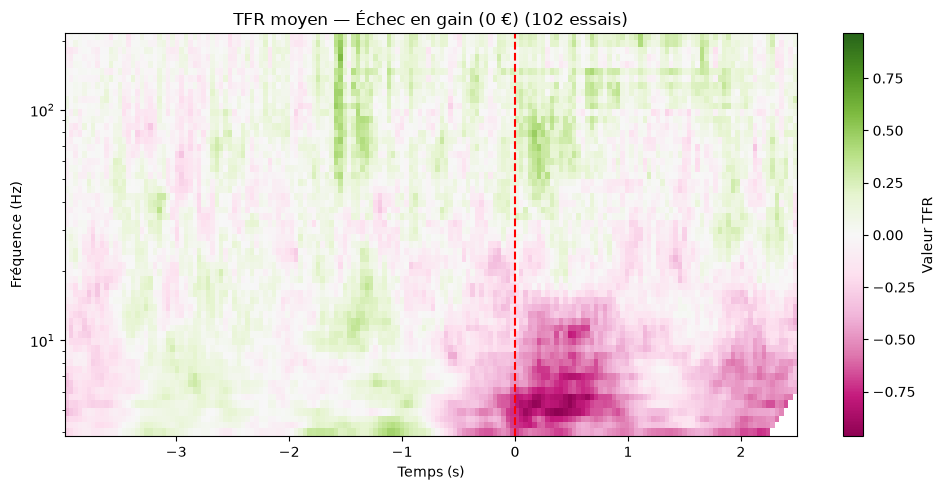

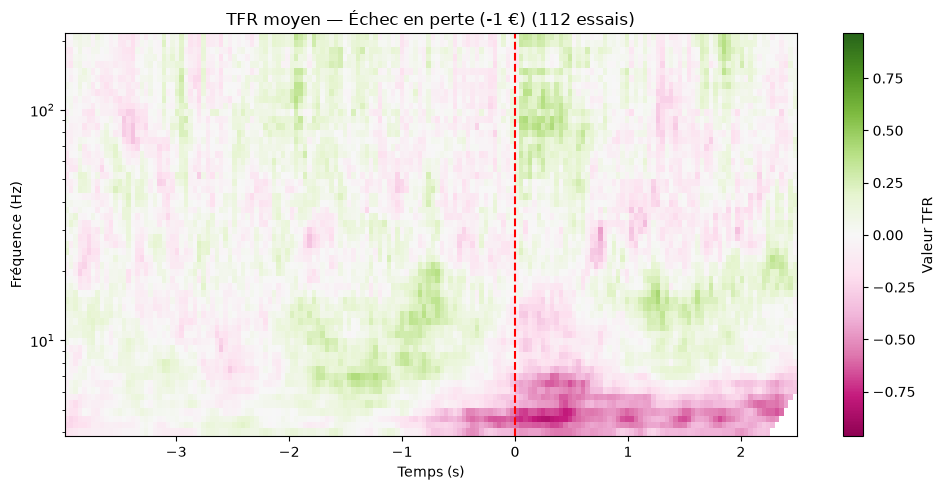

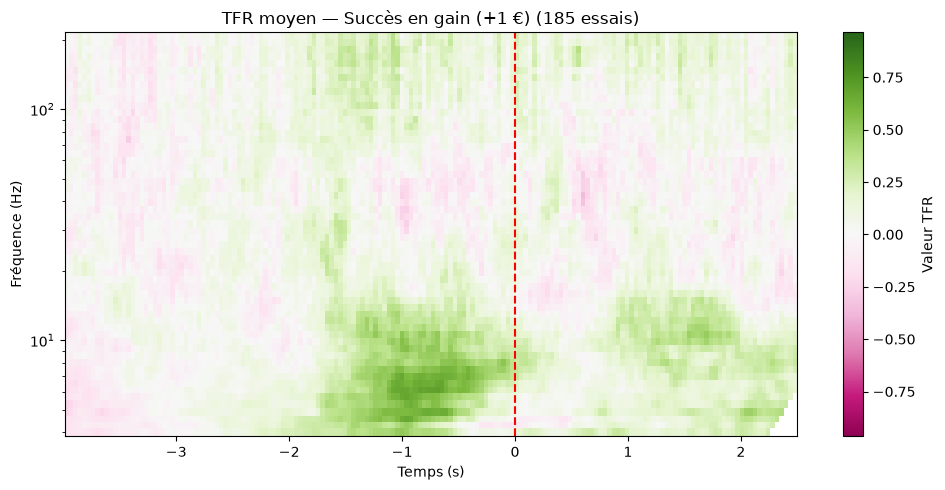

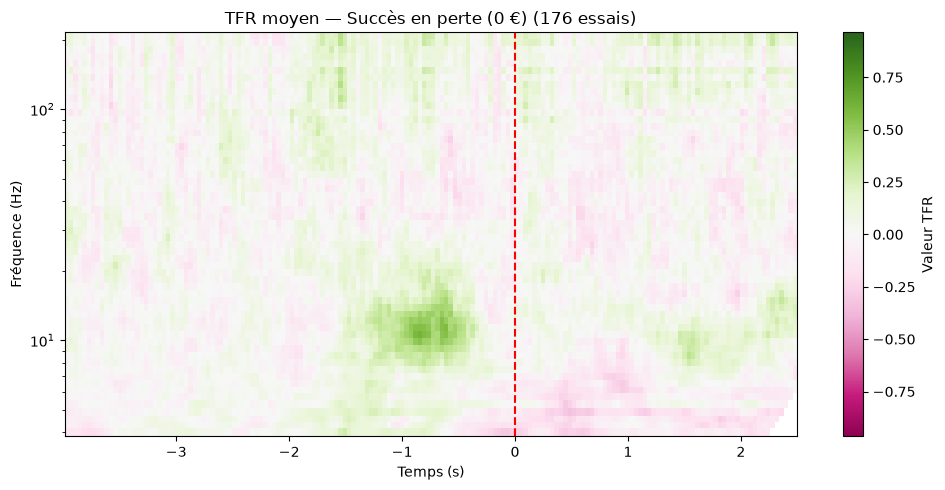

In [17]:

# ============================================================
# TFR moyen pour chacun des 4 outcomes
# ============================================================

OUTCOMES = {
    0: "Échec en gain (0 €)",
    1: "Échec en perte (-1 €)",
    2: "Succès en gain (+1 €)",
    3: "Succès en perte (0 €)",
}

# Sélection du contact à visualiser si data est en 4D
# data : (n_trials, n_freqs, n_times, n_contacts)
contact_idx = 0

# Vérification de l'alignement
if len(trial_outcome_array) != data.shape[0]:
    raise ValueError(
        f"Nombre d'outcomes ({len(trial_outcome_array)}) "
        f"différent du nombre d'essais TFR ({data_show.shape[0]})."
    )

# Sélection du contact
if data_show.ndim == 4:
    data_contact = data_show[:, :, :, contact_idx]
elif data_show.ndim == 3:
    # data : (n_trials, n_freqs, n_times)
    data_contact = data_show
else:
    raise ValueError(
        f"Dimensions de data inattendues : {data_show.shape}"
    )

# Calcul des TFR moyens pour chaque outcome
mean_tfr = {}
n_trials_outcome = {}

for outcome, label in OUTCOMES.items():

    # Indices des essais associés à cet outcome
    idx = np.flatnonzero(
        np.asarray(trial_outcome_array) == outcome
    )

    n_trials_outcome[outcome] = len(idx)

    if len(idx) == 0:
        mean_tfr[outcome] = None
        print(f"{label} : aucun essai")
        continue

    # Moyenne des TFR sur les essais
    mean_tfr[outcome] = np.nanmean(
        data_contact[idx, :, :],
        axis=0
    )

    print(f"{label} : {len(idx)} essais")

# Échelle de couleurs commune aux 4 graphiques
valid_tfrs = [
    tfr for tfr in mean_tfr.values()
    if tfr is not None
]

if not valid_tfrs:
    raise ValueError("Aucun essai valide pour les 4 outcomes.")

vmin = min(np.nanmin(tfr) for tfr in valid_tfrs)
vmax = max(np.nanmax(tfr) for tfr in valid_tfrs)
vlim = max(abs(vmin), abs(vmax))
# ============================================================
# Affichage
# ============================================================


for  outcome, label in OUTCOMES.items():

    tfr = mean_tfr[outcome]
    title = f"TFR moyen — {label} ({n_trials_outcome[outcome]} essais)"
    save_file_path = Path(f"TFR_mean_outcome_{outcome}.png")
    plot_tfr(tfr, times, freqs, trial, channel, title , cnorm=plt.Normalize(vmin=-vlim, vmax=vlim), cmap="PiYG" , horizontal_line_time = [0.0] , save_file_path = save_file_path , save_file = False) 
    


In [18]:


BANDS = {
    "Theta": (4, 8),
    "Alpha": (8, 12),
    "Beta": (12, 30),
    "Gamma": (30, 50),
    "HFA": (50, 150),
}

# 0 = échec gain (0 €)
# 1 = échec perte (-1 €)
# 2 = succès gain (+1 €)
# 3 = succès perte (0 €)




# 2. Tracer theta moyen par outcome
def plot_theta(theta, outcomes, times, channel=None):
    """
    channel=0 : affiche le signal moyen du contact 0.
    channel=None : heatmaps temps × contacts, une par outcome.
    """
    outcomes = np.asarray(outcomes)

    if channel is not None:
        if channel == "all":
            channel = np.arange(theta.shape[2])
        plt.figure(figsize=(9, 4))
        for o in range(4):
            mask = outcomes == o
            if mask.any():
                if channel.ndim == 1:
                    y = np.nanmean(theta[mask, :, channel], axis=(0, 2))
                    std_y = np.nanstd(theta[mask, :, channel], axis=(0, 2))/np.sqrt(mask.sum())
                else:
                    y = np.nanmean(theta[mask, :, channel], axis=0)
                plt.plot(times, y, label=f"Outcome {o} (n={mask.sum()})")
                plt.fill_between(
                    times,
                    y - std_y,
                    y + std_y,
                    alpha=0.2
                )
        plt.axvline(0, color="black", linestyle="--")
        plt.xlabel("Temps (s)")
        plt.ylabel("Puissance theta intégrée")
        plt.title(f"Theta moyen — contact {channel}")
        plt.legend()
        plt.tight_layout()
        plt.show()

    else:
        fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
        for o, ax in enumerate(axes.flat):
            mask = outcomes == o
            if mask.any():
                # Moyenne des essais : temps × contacts
                avg = np.nanmean(theta[mask], axis=0)
                im = ax.pcolormesh(
                    np.arange(avg.shape[1]), times, avg,
                    shading="auto"
                )
                fig.colorbar(im, ax=ax, label="Puissance theta")
                ax.set_title(f"Outcome {o} (n={mask.sum()})")
                ax.set_xlabel("Contact")
                ax.set_ylabel("Temps (s)")
        plt.tight_layout()
        plt.show()


In [19]:
# Étape 1 : intégrer les TFR par bande
band_signals = integrate_frequency(data_baseline, freqs)

shape data: (576, 166, 58, 82) trials , times , freqs , channels


In [20]:
print("bands available :", list(band_signals.keys()))

bands available : ['Theta', 'Alpha', 'Beta', 'Gamma', 'HFA']


In [21]:
# Étape 2 : visualiser theta, avec le contact 0
t_integrate_min = 0
t_integrate_max = 0.8
# Ou heatmaps temps × contacts :
# plot_theta(band_signals["Theta"], trial_outcome_array, times, channel=None)




In [22]:


def compare_outcomes_1_2(df, channel=None):
    """
    Compare outcome 1 (-1 €) et outcome 2 (+1 €) par bande.
    df contient les valeurs intégrées par essai et par bande.
    """

    bands = [b for b in BANDS if b in df.columns]
    results = []

    fig, axes = plt.subplots(
        1, len(bands), figsize=(4 * len(bands), 5), squeeze=False
    )
    axes = axes.ravel()

    for ax, band in zip(axes, bands):
        x = df.loc[df["outcome"] == 1, band].dropna().to_numpy()
        y = df.loc[df["outcome"] == 2, band].dropna().to_numpy()

        if len(x) == 0 or len(y) == 0:
            p = np.nan
        else:
            p = mannwhitneyu(x, y, alternative="two-sided").pvalue

        results.append({
            "band": band,
            "n_outcome_1": len(x),
            "n_outcome_2": len(y),
            "p_raw": p,
        })

        # Boxplot + points individuels
        ax.boxplot([x, y], positions=[1, 2], widths=0.5)
        rng = np.random.default_rng(42)
        ax.scatter(
            1 + rng.uniform(-0.08, 0.08, len(x)), x,
            alpha=0.7, s=18
        )
        ax.scatter(
            2 + rng.uniform(-0.08, 0.08, len(y)), y,
            alpha=0.7, s=18
        )

        ax.set_xticks([1, 2], ["Outcome 1\n(-1 €)", "Outcome 2\n(+1 €)"])
        ax.set_title(band)
        ax.set_ylabel("Puissance intégrée")
        ax.grid(axis="y", alpha=0.2)

    # Correction Holm sur les différentes bandes
    valid = [r for r in results if np.isfinite(r["p_raw"])]
    if valid:
        p_corrected = multipletests(
            [r["p_raw"] for r in valid], method="holm"
        )[1]
        for r, p_corr in zip(valid, p_corrected):
            r["p_holm"] = p_corr

    for r in results:
        r.setdefault("p_holm", np.nan)

    # Ajouter les p-values corrigées aux titres
    for ax, r in zip(axes, results):
        ax.set_title(f"{r['band']}\np Holm = {r['p_holm']:.3g}")

    plt.suptitle(f"Outcome 1 vs 2 — contact {channel}")
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results)


## Channels grouping using julich and mni data
Position of electrodes have been used in MNI space to redirect to julich area (done in JULICH_ATLAS_PARTIALISATION project using sibraa and PBLT_ROIS.csv) We want to do analysis only on insula ventral or dorsal data.
csv is loaded Julich folder

In [23]:
bipolar_chanlist = get_chanlist_from_info(info)

In [24]:

importlib.reload(sys.modules['paths_data'])

from paths_data import path_to_julich_output , PBLT_ROI_csv_name
#reload paths data:
ROIS = pd.read_csv(Path(path_to_julich_output) / PBLT_ROI_csv_name , delimiter=";")


In [25]:
first_contacts , second_contacts = bipolar_to_monopolar(bipolar_chanlist, ROIS['CHAN'].values)
bipolar_chanlist = get_chanlist_from_info(info)

classification = classify_contacts_insula(
    ROIS=ROIS,
    first_contacts=first_contacts,
    patient="GRE_2014_AUDe"
)

display(classification[classification["classification"] != "outside"])

,contact,classification
7,X'2,Ventrale
8,X'03,Ventrale
9,X07,Dorsale
68,Q02,Dorsale


=======================Ventrale CONTACTS================================
=== Contact X'2 (index 7) ===


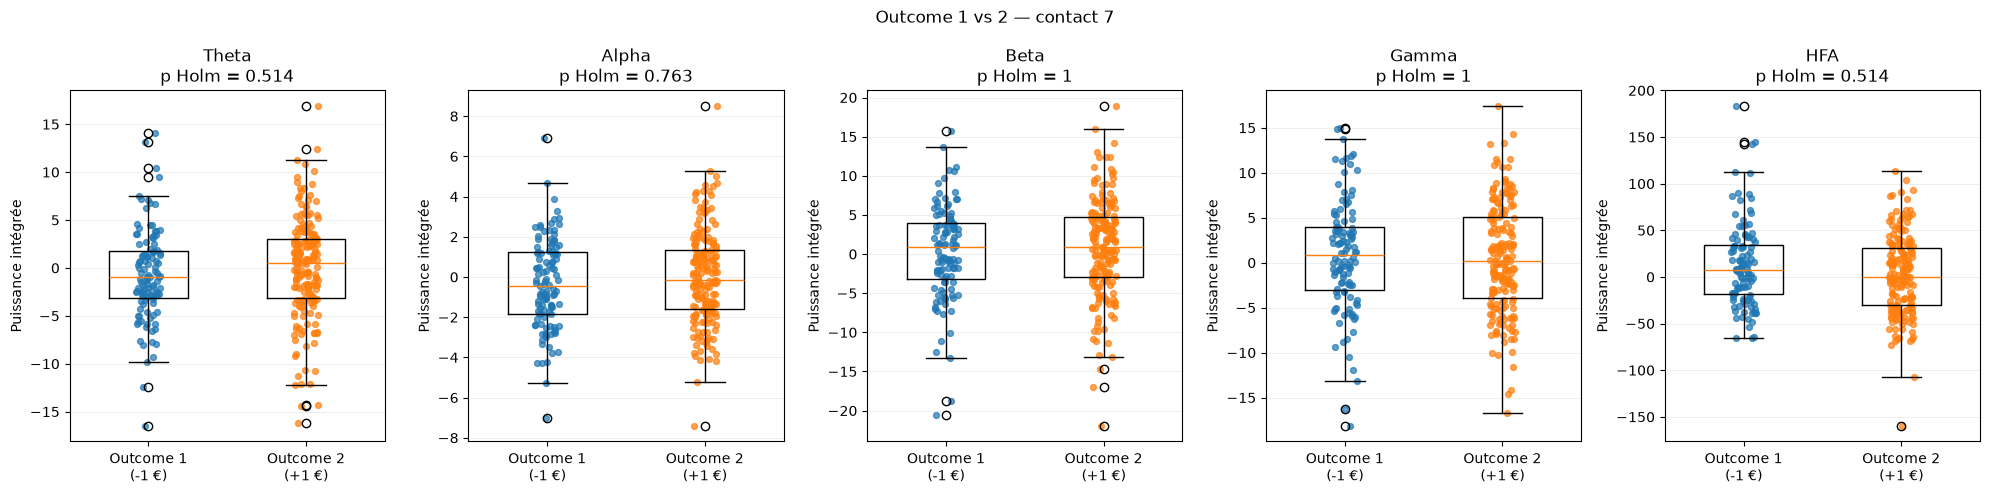

,band,n_outcome_1,n_outcome_2,p_raw,p_holm
0,Theta,112,185,0.102728,0.513639
1,Alpha,112,185,0.254428,0.763284
2,Beta,112,185,0.541922,1.000000
3,Gamma,112,185,0.523609,1.000000
4,HFA,112,185,0.127055,0.513639


=== Contact X'03 (index 8) ===


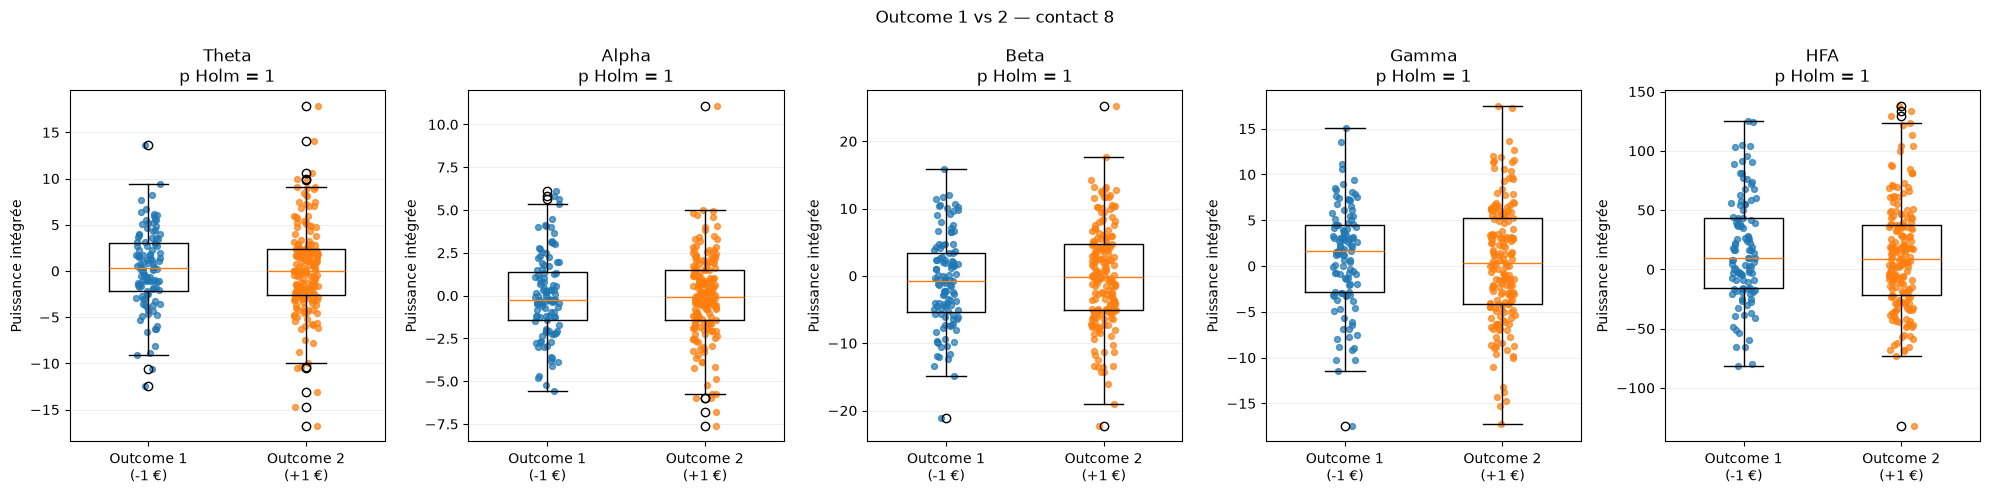

,band,n_outcome_1,n_outcome_2,p_raw,p_holm
0,Theta,112,185,0.665115,1.0
1,Alpha,112,185,0.844713,1.0
2,Beta,112,185,0.312490,1.0
3,Gamma,112,185,0.245816,1.0
4,HFA,112,185,0.333647,1.0


=======================DORSALE CONTACTS================================
=== Contact X07 (index 9) ===


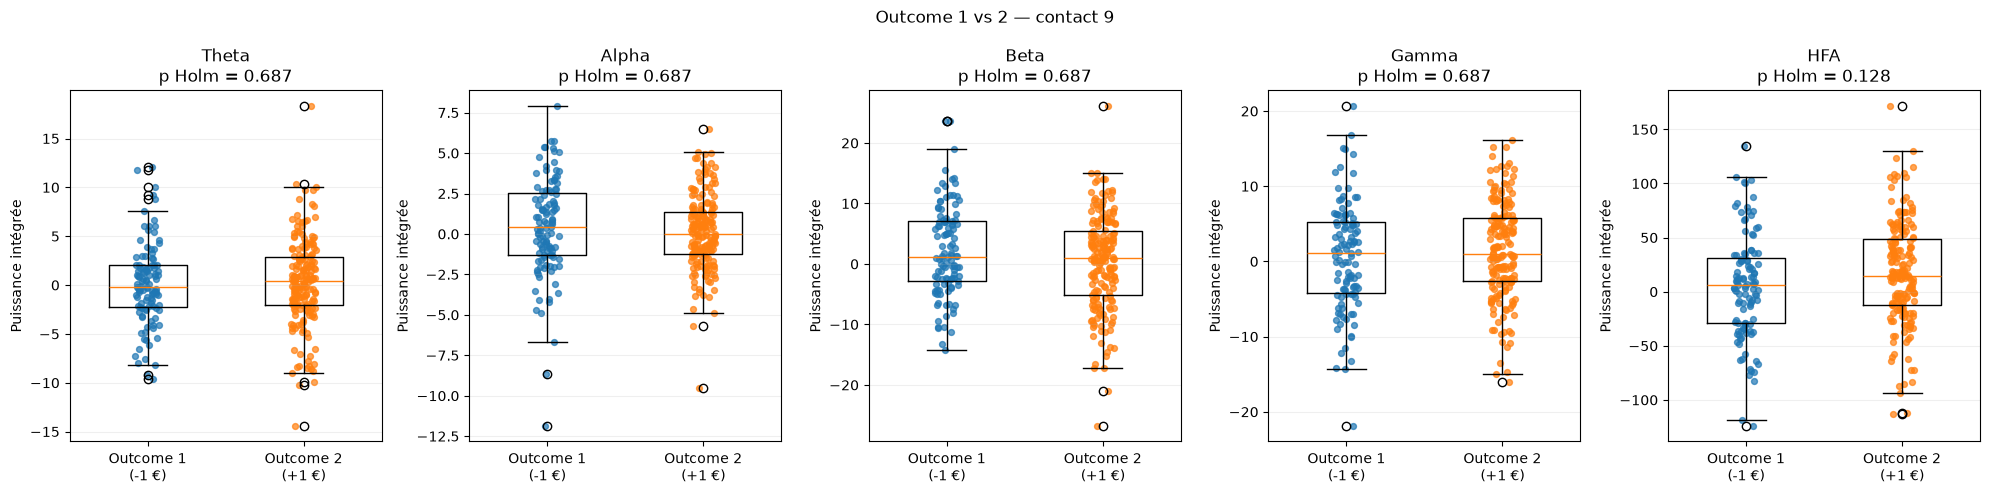

,band,n_outcome_1,n_outcome_2,p_raw,p_holm
0,Theta,112,185,0.484470,0.686633
1,Alpha,112,185,0.182846,0.686633
2,Beta,112,185,0.171658,0.686633
3,Gamma,112,185,0.264439,0.686633
4,HFA,112,185,0.025574,0.127870


=== Contact Q02 (index 68) ===


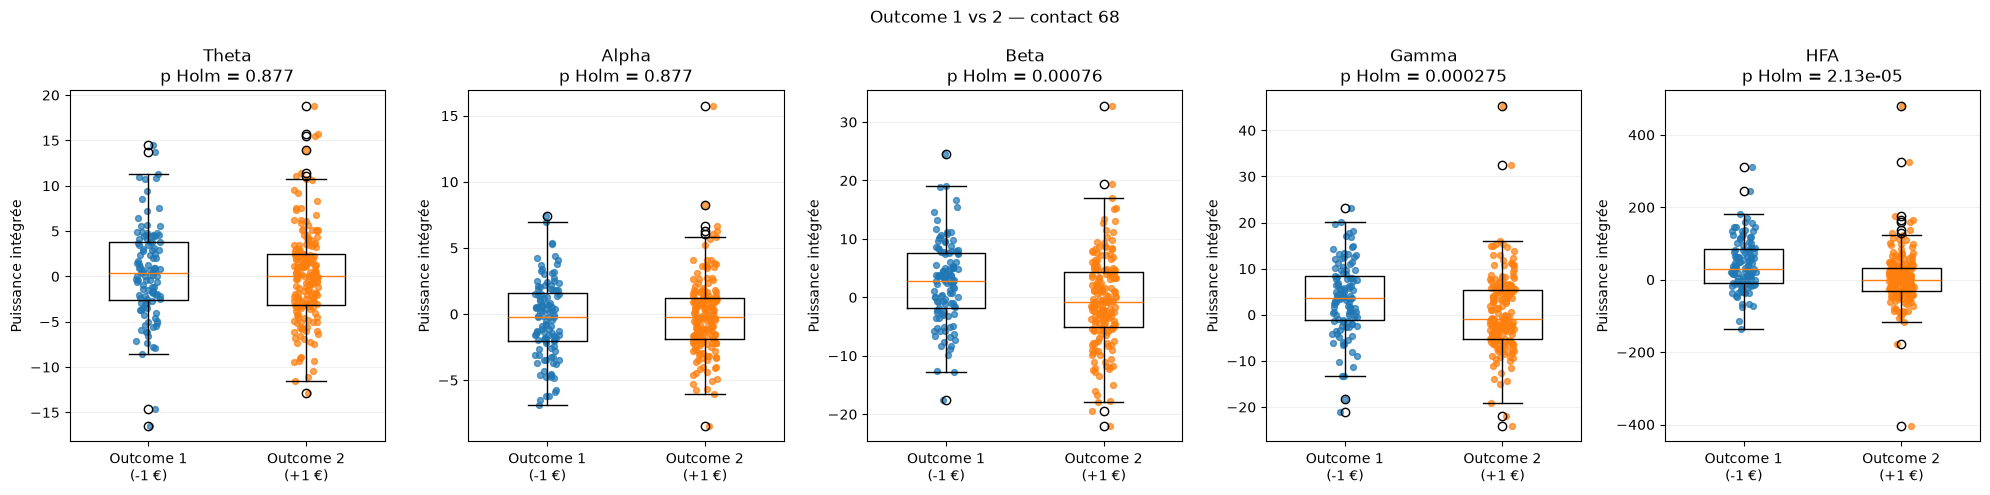

,band,n_outcome_1,n_outcome_2,p_raw,p_holm
0,Theta,112,185,0.438688,0.877375
1,Alpha,112,185,0.693708,0.877375
2,Beta,112,185,0.000253,0.000760
3,Gamma,112,185,0.000069,0.000275
4,HFA,112,185,0.000004,0.000021


In [26]:
print("=======================Ventrale CONTACTS================================")

for ch_idx, ch_name in classification[classification["classification"] == "Ventrale"]["contact"].items():
    print(f"=== Contact {ch_name} (index {ch_idx}) ===")
    # Étape 3 : intégrer entre 0 et 0.8 s, sur le contact 0

    df = integrate_time(
        band_signals, times, trial_outcome_array,
        tmin=t_integrate_min, tmax=t_integrate_max, channel=ch_idx
    )


    results = compare_outcomes_1_2(df, channel=ch_idx)
    display(results) 
print("=======================DORSALE CONTACTS================================")
for ch_idx, ch_name in classification[classification["classification"] == "Dorsale"]["contact"].items():
    print(f"=== Contact {ch_name} (index {ch_idx}) ===")
    # Étape 3 : intégrer entre 0 et 0.8 s, sur le contact 0

    df = integrate_time(
        band_signals, times, trial_outcome_array,
        tmin=t_integrate_min, tmax=t_integrate_max, channel=ch_idx
    )


    results = compare_outcomes_1_2(df, channel=ch_idx)
    display(results) 

In [35]:
results_stats_all_patients = pd.read_csv(r'C:\Users\Robin\Documents\THESE_CODE\PROJET_META_ANALYSE\Data_manadgement\outputs\analyse_pblt\resultats_statistiques_tous_patients.csv')
print(results_stats_all_patients[results_stats_all_patients["band"]=="HFA"].sum())

patient                        GRE_2014_AUDeGRE_2014_AUDeGRE_2014_AUDeGRE_201...
position                       ventralventraldorsaldorsaldorsaldorsaldorsalve...
contact_index                                                               3705
contact                        X'2X'03X07Q02X'03X'04X'05X'2X'03X'04X'2X'03X'0...
band                           HFAHFAHFAHFAHFAHFAHFAHFAHFAHFAHFAHFAHFAHFAHFAH...
n_outcome_1                                                                 8015
n_outcome_2                                                                12725
median_outcome_1                                                     6661.860958
median_outcome_2                                                     6589.130213
median_difference_2_minus_1                                           -72.730745
p_raw                                                                  27.326268
p_holm                                                                 44.200456
significant                 

In [38]:
print(len(results_stats_all_patients[results_stats_all_patients["band"]=="HFA"]))

87


In [1]:
liste_v_d = "DorsalDorsalDorsalDorsalDorsalVentralDorsalVentralDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalDorsalVentralVentralDorsalDorsalDorsalDorsalDorsalVentralDorsalDorsalDorsalVentralDorsalDorsalDorsalDorsalVentralVentralDorsalDorsalVentralVentralVentralDorsalVentralVentralDorsalDorsalDorsalVentralVentralDorsalDorsalDorsalVentralDorsalDorsalDorsalDorsalVentralDorsalDorsalDorsalDorsalVentralVentralDorsalDorsalDorsalDorsalVentralVentralVentralVentralVentralVentralDorsalDorsal"
count_dorsal = liste_v_d.count("Dorsal")
count_ventral = liste_v_d.count("Ventral")
print(f"Nombre de contacts dorsaux : {count_dorsal}")
print(f"Nombre de contacts ventraux : {count_ventral}")

Nombre de contacts dorsaux : 57
Nombre de contacts ventraux : 25
